# Exploring the results

This notebook explores the data and the results of the full experiment
(`python -m tsr.experiment`). It does no training: it reads the cached dataset
and `results/results.csv`, so it runs in seconds.

1. **The data**: what the signs look like and how balanced the classes are
2. **Degradation**: how much of its clean accuracy each model loses
3. **Is the augmentation gain real?** Compare the gain with the variation between seeds
4. **Where does the old method win?** Severities where HOG + SVM beats the CNN

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Run from either the repo root or the notebooks/ folder.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

data = np.load(ROOT / "data" / "processed" / "gtsrb_32.npz")
x_train, y_train = data["x_train"], data["y_train"]
results = pd.read_csv(ROOT / "results" / "results.csv")

print(f"Training images: {len(x_train):,}  |  Result rows: {len(results):,}")
results.head()

Training images: 26,640  |  Result rows: 234


,seed,model,train,corruption,severity,seen_in_training,accuracy,macro_f1,latency_ms,size_mb
0,0,hog_svm,clean,clean,0,False,0.899604,0.880048,0.950167,0.60716
1,0,hog_svm,clean,gaussian_noise,1,False,0.631750,0.611931,0.950167,0.60716
2,0,hog_svm,clean,gaussian_noise,2,False,0.437688,0.406440,0.950167,0.60716
3,0,hog_svm,clean,gaussian_noise,3,False,0.321378,0.266064,0.950167,0.60716
4,0,hog_svm,clean,gaussian_noise,4,False,0.211639,0.150391,0.950167,0.60716


## 1. The data

One example image per class. Many signs look alike (the speed limits in
particular), and some images are very dark even before any corruption is added.

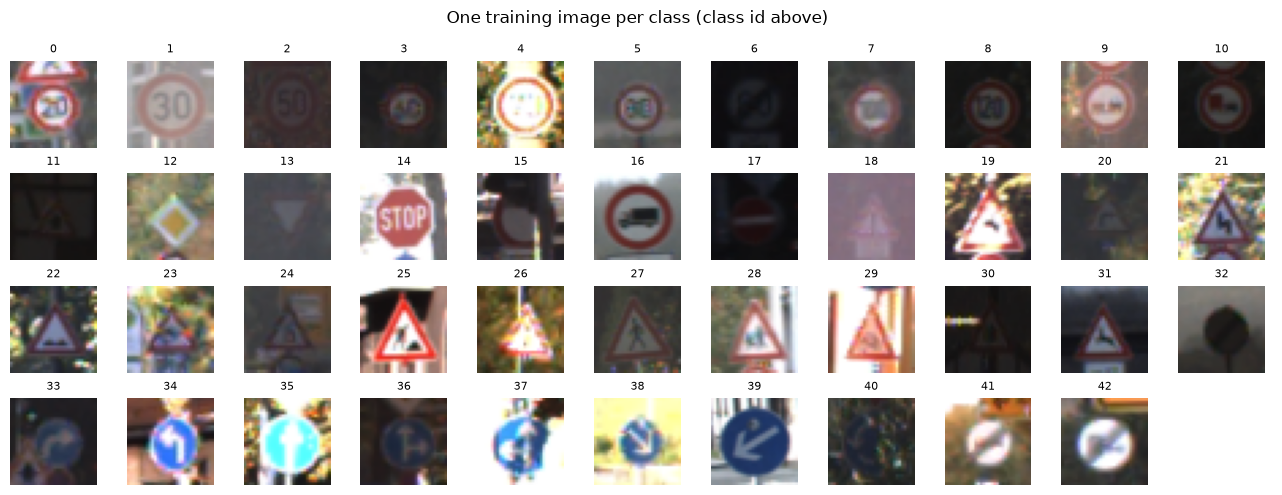

In [2]:
fig, axes = plt.subplots(4, 11, figsize=(13, 5))
for c, ax in enumerate(axes.flat):
    ax.axis("off")
    if c < 43:
        ax.imshow(x_train[np.flatnonzero(y_train == c)[0]])
        ax.set_title(str(c), fontsize=8)
fig.suptitle("One training image per class (class id above)")
plt.tight_layout()
plt.show()

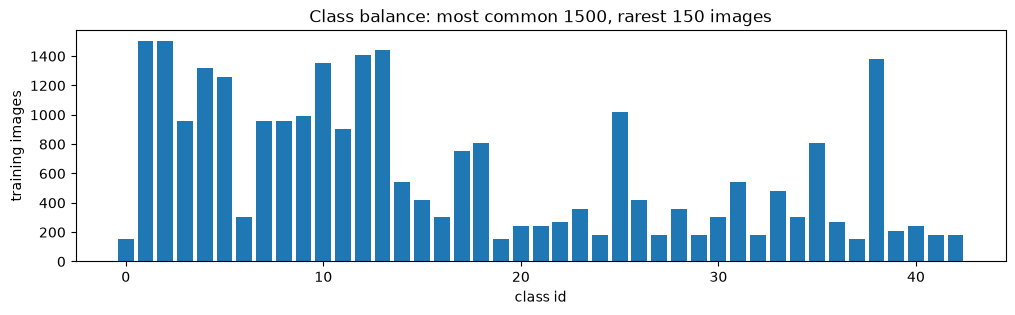

In [3]:
counts = np.bincount(y_train, minlength=43)
plt.figure(figsize=(12, 3))
plt.bar(range(43), counts)
plt.xlabel("class id")
plt.ylabel("training images")
plt.title(f"Class balance: most common {counts.max()}, rarest {counts.min()} images")
plt.show()

The classes are **imbalanced**: the most common class has roughly ten times as many
images as the rarest. A model can get high accuracy by doing well on the common
signs alone. That is why the experiment also reports **macro-F1**, where every
class counts equally.

## 2. Degradation: how much of the clean accuracy is lost?

Absolute accuracy mixes two things: how good a model is in general, and how
robust it is. The **relative drop**, `(clean - corrupted) / clean`, isolates the
robustness. 0% means nothing is lost and 100% means everything is lost.

In [4]:
clean = (
    results[results["corruption"] == "clean"]
    .groupby(["model", "train", "seed"])["accuracy"]
    .first()
)
worst = results[results["severity"] == 5].copy()
worst["clean_acc"] = [
    clean[(m, t, s)] for m, t, s in zip(worst["model"], worst["train"], worst["seed"], strict=True)
]
worst["relative_drop"] = (worst["clean_acc"] - worst["accuracy"]) / worst["clean_acc"]

drop = worst.groupby(["model", "train", "corruption"])["relative_drop"].mean().unstack("corruption")
(drop * 100).round(0).astype(int).astype(str) + " %"

corruption         blur darkness   fog gaussian_noise  rain
model   train                                              
cnn     augmented  46 %     16 %  30 %           38 %  65 %
        clean      54 %     47 %  60 %           61 %  66 %
hog_svm clean      73 %      1 %  41 %           85 %  83 %

At the worst severity, the clean-trained CNN loses about half its accuracy on
every corruption. Augmentation cuts the loss sharply for noise, darkness and fog,
which it was trained on, but much less for blur and almost not at all for rain.
HOG + SVM loses almost nothing in darkness and almost everything under noise.

## 3. Is the augmentation gain real, or just noise between seeds?

Every configuration was trained with 3 seeds. If the gain from augmentation is
smaller than the spread between seeds, we cannot claim it is real. Here, per
corruption: gain = augmented CNN minus clean CNN (mean over severities), compared
with the largest standard deviation across seeds.

In [5]:
cnn = results[(results["model"] == "cnn") & (results["corruption"] != "clean")]
per_seed = cnn.groupby(["train", "corruption", "seed"])["accuracy"].mean()
mean = per_seed.groupby(["train", "corruption"]).mean().unstack("train")
std = per_seed.groupby(["train", "corruption"]).std().unstack("train")

table = pd.DataFrame(
    {
        "gain (pp)": (mean["augmented"] - mean["clean"]) * 100,
        "seed std (pp)": std.max(axis=1) * 100,
    }
)
table["clear?"] = np.where(table["gain (pp)"] > 2 * table["seed std (pp)"], "yes", "no")
table.round(1)

,gain (pp),seed std (pp),clear?
corruption,,,
blur,4.8,2.6,no
darkness,17.2,1.2,yes
fog,17.2,8.3,yes
gaussian_noise,12.6,1.8,yes
rain,1.3,2.9,no


**pp** = percentage points. A rule of thumb: a gain larger than about twice the
seed spread is unlikely to be luck. The gains on the *seen* corruptions (noise,
darkness, fog) are clear. Blur is borderline, and the gain on rain is within the
noise between seeds.

## 4. Where does the old method win?

For each corruption and severity: does HOG + SVM beat the clean-trained CNN?

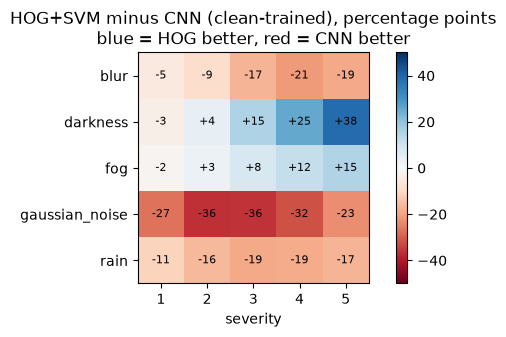

In [6]:
acc = (
    results[results["corruption"] != "clean"]
    .groupby(["model", "train", "corruption", "severity"])["accuracy"]
    .mean()
)
hog = acc.loc[("hog_svm", "clean")]
cnn_clean = acc.loc[("cnn", "clean")]
diff = ((hog - cnn_clean) * 100).unstack("severity").round(1)

ax = plt.figure(figsize=(7, 3)).gca()
im = ax.imshow(diff.values, cmap="RdBu", vmin=-50, vmax=50)
ax.set_xticks(range(diff.shape[1]), diff.columns)
ax.set_yticks(range(diff.shape[0]), diff.index)
for i in range(diff.shape[0]):
    for j in range(diff.shape[1]):
        ax.text(j, i, f"{diff.values[i, j]:+.0f}", ha="center", va="center", fontsize=8)
ax.set_xlabel("severity")
ax.set_title(
    "HOG+SVM minus CNN (clean-trained), percentage points\nblue = HOG better, red = CNN better"
)
plt.colorbar(im)
plt.show()

HOG + SVM wins in **darkness and fog from severity 2 upwards**. The CNN wins
everywhere else, by a wide margin under noise and rain. That suggests an idea
for future work: the two models fail in different situations, so combining them
(or adding brightness normalisation to the CNN's input) could beat both.

## Conclusions

- The dataset is imbalanced, so macro-F1 is reported alongside accuracy.
- Relative drop shows that the clean-trained CNN loses about half its accuracy at
  the worst severity, and augmentation mainly helps on the corruptions it was
  trained on.
- The augmentation gains on seen corruptions are larger than the seed-to-seed
  variation. Blur is borderline and rain is not.
- HOG + SVM is not simply worse: it is better in darkness, which points to
  combining models as a next step.